In [78]:
import pandas as pd
from tqdm import tqdm
import seaborn as sns
import matplotlib.pylab as plt
from matplotlib.pyplot import figure

In [79]:
s=pd.read_pickle("../03_clear_cases/clear-fusion_tama_augustus.pkl")

In [80]:
s

,gene,isoform,accession,associated_gene,associated_transcript,exons,length,isoform_read_support,gene_read_support,structural_category,subcategory,Sqanti_ORF_seq,cat_assign,association,cat_read_support,gene_association_read_support,type,isoforms_per_gene,ORFs_per_gene,isoforms_per_ORFs
0,G1128,G1128.10,at6923,g1555,novel,1,3275,1,59,genic,mono-exon,MGNCVSLDVSCHHQTLNHACGCLFGDGNYIHMMEANLEALEKTIQE...,one2one,1,59,12,nlr,11,2,8.0
1,G1128,G1128.11,at6923,g1555,novel,1,2744,1,59,genic,mono-exon,MDGVLTFTVKMHDVIREMALWIASKFGKQKETLCVRSGAQLRQIPK...,one2one,1,59,12,nlr,11,2,3.0
2,G1128,G1128.12,at6923,g1555,novel,1,2795,1,59,genic,mono-exon,MDGVLTFTVKMHDVIREMALWIASKFGKQKETLCVRSGAQLRQIPK...,one2one,1,59,12,nlr,11,2,3.0
3,G1128,G1128.13,at6923,g1555,novel,1,1821,1,59,genic,mono-exon,MDGVLTFTVKMHDVIREMALWIASKFGKQKETLCVRSGAQLRQIPK...,one2one,1,59,12,nlr,11,2,3.0
4,G1128,G1128.2,at6923,g1555,novel,2,3331,1,59,novel_not_in_catalog,intron_retention,MGNCVSLDVSCHHQTLNHACGCLFGDGNYIHMMEANLEALEKTIQE...,one2one,1,59,12,nlr,11,2,8.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3419863,G16302,G16302.24,col0,ATCG01310_ATCG01300,novel,2,818,1,136,fusion,multi-exon,MAIHLYKTSTPSTRNGAVDSQVKSNPRNNLICGQHHCGKGRNARGI...,fusion,2,15,15,other,49,8,2.0
3419864,G16302,G16302.26,col0,ATCG01310_ATCG01300,novel,2,831,2,136,fusion,multi-exon,MAIHLYKTSTPSTRNGAVDSQVKSNPRNNLICGQHHCGKGRNARGI...,fusion,2,15,15,other,49,8,4.0
3419865,G16302,G16302.5,col0,ATCG01310_ATCG01300,novel,2,1204,1,136,fusion,multi-exon,MAIHLYKTSTPSTRNGAVDSQVKSNPRNNLICGQHHCGKGRNARGI...,fusion,2,15,15,other,49,8,4.0
3419866,G16302,G16302.7,col0,ATCG01310_ATCG01300,novel,2,1141,6,136,fusion,multi-exon,MAIHLYKTSTPSTRNGAVDSQVKSNPRNNLICGQHHCGKGRNARGI...,fusion,2,15,15,other,49,8,4.0


In [81]:
nlrs=s.loc[s["type"]=="nlr"]

In [82]:
nlrs=nlrs[["gene","accession","gene_read_support"]]

In [83]:
nlrs.drop_duplicates(inplace=True)

In [84]:
for acc in nlrs["accession"].unique().tolist():
    ref=nlrs.loc[nlrs["accession"]==acc]
    print(ref["gene"].value_counts())

G1128     1
G12596    1
G14991    1
G14934    1
G14933    1
         ..
G767      1
G3843     1
G3842     1
G3841     1
G15256    1
Name: gene, Length: 126, dtype: int64
G1041     1
G13056    1
G14559    1
G14558    1
G14449    1
         ..
G786      1
G785      1
G705      1
G3625     1
G14275    1
Name: gene, Length: 117, dtype: int64
G1097     1
G13008    1
G14810    1
G14762    1
G14710    1
         ..
G4696     1
G832      1
G831      1
G824      1
G11219    1
Name: gene, Length: 124, dtype: int64
G1109     1
G11692    1
G13892    1
G13842    1
G13787    1
         ..
G757      1
G753      1
G752      1
G674      1
G14135    1
Name: gene, Length: 118, dtype: int64
G1081     1
G14620    1
G15124    1
G15061    1
G15049    1
         ..
G815      1
G735      1
G3825     1
G3824     1
G13972    1
Name: gene, Length: 124, dtype: int64
G1099     1
G13146    1
G15058    1
G14944    1
G14931    1
         ..
G832      1
G827      1
G740      1
G3795     1
G11366    1
Name: gene, Length

In [85]:
lengths=[]
for acc in nlrs["accession"].unique().tolist():
    ref=nlrs.loc[nlrs["accession"]==acc]
    lengths.append(len(ref))
print(lengths)

[126, 117, 124, 118, 124, 124, 128, 129, 138, 130, 130, 116, 132, 125, 118, 125, 127, 123]


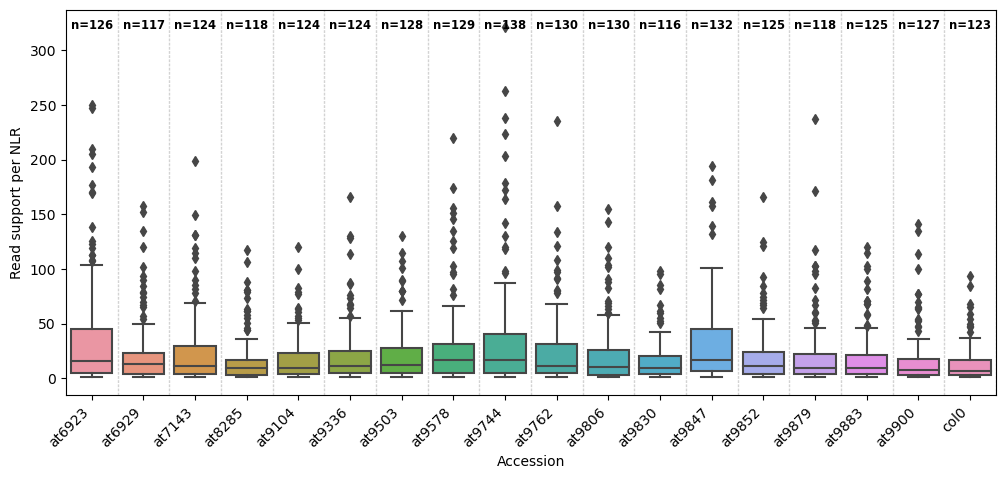

In [86]:
sns.set_palette(sns.color_palette("colorblind"))
figure(figsize=(12, 5))

nlr_box = sns.boxplot(data=nlrs, 
                          x="accession", y="gene_read_support")

nlr_box.set_xticklabels(nlrs["accession"].unique().tolist(), rotation=45,horizontalalignment='right')
nlr_box.set_xlabel("Accession")
nlr_box.set_ylabel("Read support per NLR")

[nlr_box.axvline(x+.5,color='lightgrey', dashes=(2,1), linewidth=1) for x in nlr_box.get_xticks()]

for i,j in enumerate(lengths):
    plt.text(i-0.40, 320, f"n={j}", horizontalalignment='left', size='small', color='black', weight='semibold')

fig = nlr_box.get_figure()
fig.savefig("nlr_rs.png", bbox_inches='tight')

In [87]:
nlrs_sum=nlrs[["accession","gene_read_support"]].groupby(by="accession").apply("sum").reset_index()

In [88]:
nlrs_sum

,accession,gene_read_support
0,at6923,4819
1,at6929,2750
2,at7143,3031
3,at8285,2059
4,at9104,2217
5,at9336,2759
6,at9503,2860
7,at9578,3687
8,at9744,5056
9,at9762,3315


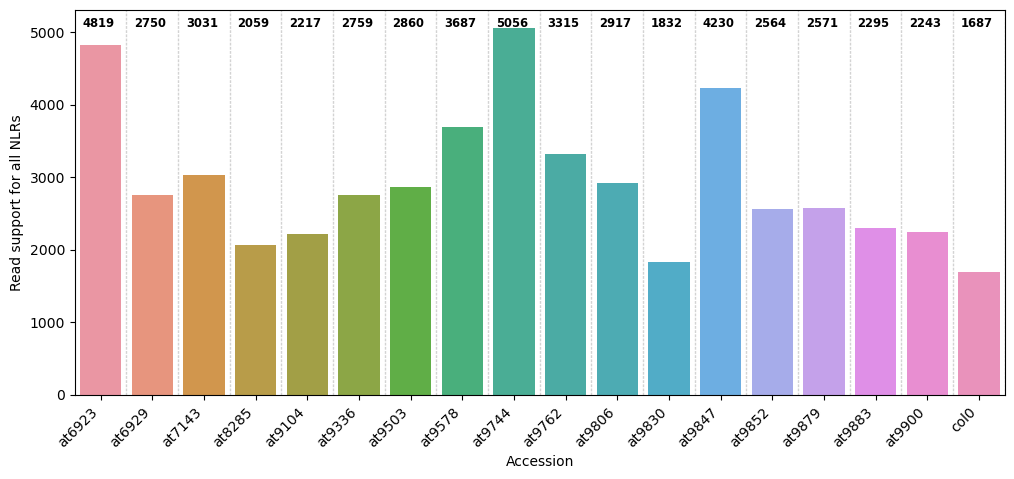

In [89]:
sns.set_palette(sns.color_palette("colorblind"))
figure(figsize=(12, 5))

nlr_bar = sns.barplot(data=nlrs_sum, 
                          x="accession", y="gene_read_support")

nlr_bar.set_xticklabels(nlrs["accession"].unique().tolist(), rotation=45,horizontalalignment='right')
nlr_bar.set_xlabel("Accession")
nlr_bar.set_ylabel("Read support for all NLRs")

[nlr_bar.axvline(x+.5,color='lightgrey', dashes=(2,1), linewidth=1) for x in nlr_bar.get_xticks()]

for i,j in enumerate(nlrs_sum["gene_read_support"].tolist()):
    plt.text(i-0.35, 5070, f"{j}", horizontalalignment='left', size='small', color='black', weight='semibold')
    
fig = nlr_bar.get_figure()
fig.savefig("nlr_sum_rs.png", bbox_inches='tight')

### Normalize

In [90]:
s=pd.read_pickle("../03_clear_cases/clear-fusion_tama_augustus.pkl")

In [91]:
sub=s[["gene","accession","gene_read_support","type"]]

In [92]:
total=sub[["gene","accession","gene_read_support"]].drop_duplicates()
total_dict={}
for acc in total["accession"].unique().tolist():
    ref=total.loc[total["accession"]==acc]
    reads=ref["gene_read_support"].sum()
    #print(type(reads))
    total_dict[acc]=reads
    print(ref["gene_read_support"].sum())
    #sub.loc[sub["accession"]==ref]["total_reads"]=reads

769191
528839
605081
400958
551320
641851
591406
832853
582217
473174
410115
433771
700431
424710
408896
395807
579311
473026


In [93]:
sub.drop_duplicates(inplace=True)

/tmp/ipykernel_236048/42837252.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  sub.drop_duplicates(inplace=True)


In [94]:
nlrs_prop=pd.DataFrame()
for acc in sub["accession"].unique().tolist():
    ref=sub.loc[sub["accession"]==acc].copy()
    ref["normalized_reads"]=ref["gene_read_support"]/total_dict[acc]
    nlrs_prop=pd.concat([nlrs_prop, ref])
    #print(ref["gene"].value_counts())
print(nlrs_prop)

           gene accession  gene_read_support   type  normalized_reads
0         G1128    at6923                 59    nlr          0.000077
11        G1245    at6923                  8    nlr          0.000010
18        G1246    at6923                  2    nlr          0.000003
20        G1795    at6923                  3    nlr          0.000004
22        G1796    at6923                 11    nlr          0.000014
...         ...       ...                ...    ...               ...
3419291  G12715      col0                  1  other          0.000002
3419328  G13821      col0                  6  other          0.000013
3419368  G14299      col0                  2  other          0.000004
3419386  G14982      col0                  1  other          0.000002
3419428  G15691      col0                  1  other          0.000002

[285435 rows x 5 columns]


In [95]:
nlrs_prop=nlrs_prop.loc[nlrs_prop["type"]=="nlr"]

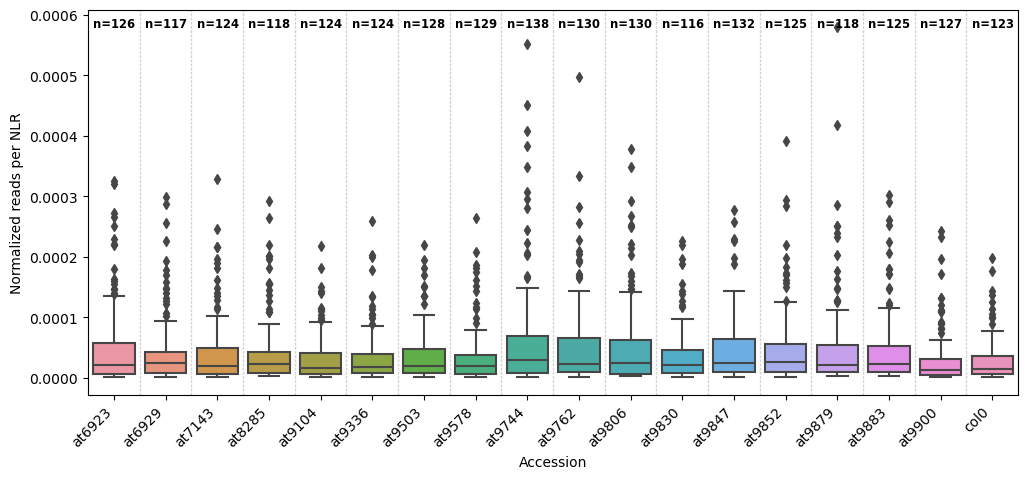

In [96]:
sns.set_palette(sns.color_palette("colorblind"))
figure(figsize=(12, 5))

nlr_box = sns.boxplot(data=nlrs_prop, 
                          x="accession", y="normalized_reads")

nlr_box.set_xticklabels(nlrs_prop["accession"].unique().tolist(), rotation=45,horizontalalignment='right')
nlr_box.set_xlabel("Accession")
nlr_box.set_ylabel("Normalized reads per NLR")

[nlr_box.axvline(x+.5,color='lightgrey', dashes=(2,1), linewidth=1) for x in nlr_box.get_xticks()]

for i,j in enumerate(lengths):
    plt.text(i-0.40, 0.00058, f"n={j}", horizontalalignment='left', size='small', color='black', weight='semibold')

fig = nlr_box.get_figure()
fig.savefig("nlr_rs_norm.png", bbox_inches='tight')

In [97]:
nlrs_prop_sum=nlrs_prop[["accession","normalized_reads"]].groupby(by="accession").apply("sum").reset_index()

In [98]:
nlrs_prop_sum

,accession,normalized_reads
0,at6923,0.006265
1,at6929,0.005200
2,at7143,0.005009
3,at8285,0.005135
4,at9104,0.004021
5,at9336,0.004299
6,at9503,0.004836
7,at9578,0.004427
8,at9744,0.008684
9,at9762,0.007006


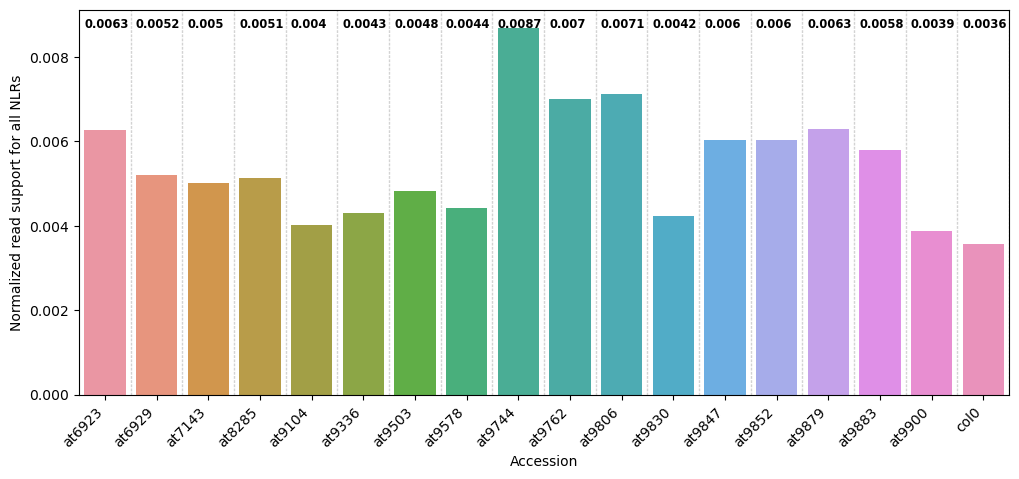

In [99]:
sns.set_palette(sns.color_palette("colorblind"))
figure(figsize=(12, 5))

nlr_bar = sns.barplot(data=nlrs_prop_sum, 
                          x="accession", y="normalized_reads")

nlr_bar.set_xticklabels(nlrs_prop_sum["accession"].unique().tolist(), rotation=45,horizontalalignment='right')
nlr_bar.set_xlabel("Accession")
nlr_bar.set_ylabel("Normalized read support for all NLRs")

[nlr_bar.axvline(x+.5,color='lightgrey', dashes=(2,1), linewidth=1) for x in nlr_bar.get_xticks()]

for i,j in enumerate(nlrs_prop_sum["normalized_reads"].tolist()):
    plt.text(i-0.4, 0.0087, f"{round(j, 4)}", horizontalalignment='left', size='small', color='black', weight='semibold')
    
fig = nlr_bar.get_figure()
fig.savefig("nlr_sum_rs_norm.png", bbox_inches='tight')